<a href="https://colab.research.google.com/github/sjensen39/CS133_GP1/blob/main/project_class_notebooks/ML_data_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

High sales season prediction: regression or time-series

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#!pip install pandas openpyxl

In [5]:
df = pd.read_excel('https://github.com/sjensen39/CS133_GP1/raw/main/dataset/Amazon%202_Raw.xlsx')
df.head()

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order ID      3203 non-null   object        
 1   Order Date    3203 non-null   datetime64[ns]
 2   Ship Date     3203 non-null   datetime64[ns]
 3   EmailID       3203 non-null   object        
 4   Geography     3203 non-null   object        
 5   Category      3203 non-null   object        
 6   Product Name  3203 non-null   object        
 7   Sales         3203 non-null   float64       
 8   Quantity      3203 non-null   int64         
 9   Profit        3203 non-null   float64       
dtypes: datetime64[ns](2), float64(2), int64(1), object(5)
memory usage: 250.4+ KB


In [7]:
df.describe()

,Order Date,Ship Date,Sales,Quantity,Profit
count,3203,3203,3203.000000,3203.000000,3203.000000
mean,2013-05-10 03:06:07.530440192,2013-05-14 01:25:25.195129600,226.493233,3.828910,33.849032
min,2011-01-07 00:00:00,2011-01-09 00:00:00,0.990000,1.000000,-3399.980000
25%,2012-05-22 00:00:00,2012-05-26 00:00:00,19.440000,2.000000,3.852000
50%,2013-07-22 00:00:00,2013-07-25 00:00:00,60.840000,3.000000,11.166400
75%,2014-05-23 00:00:00,2014-05-27 00:00:00,215.809000,5.000000,33.000400
max,2014-12-31 00:00:00,2015-01-06 00:00:00,13999.960000,14.000000,6719.980800
std,NaN,NaN,524.876877,2.260947,174.109081


In [8]:
# Create the df DataFrame as a copy of the original
df_dates = df.copy()

# Extract Year and Month for Order Date
df_dates['Order Year'] = df_dates['Order Date'].dt.year
df_dates['Order Month'] = df_dates['Order Date'].dt.month
df_dates['Order Day'] = df_dates['Order Date'].dt.day

# Extract Year and Month for Ship Date
df_dates['Ship Year'] = df_dates['Ship Date'].dt.year
df_dates['Ship Month'] = df_dates['Ship Date'].dt.month
df_dates['Ship Day'] = df_dates['Ship Date'].dt.day

# Drop the original datetime columns
df_dates.drop(columns=['Order Date', 'Ship Date'], inplace=True)

# Display the new DataFrame's columns and first few rows
display(df_dates.head())

,Order ID,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,Order Year,Order Month,Order Day,Ship Year,Ship Month,Ship Day
0,CA-2013-138688,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714,2013,6,13,2013,6,17
1,CA-2011-115812,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694,2011,6,9,2011,6,14
2,CA-2011-115812,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656,2011,6,9,2011,6,14
3,CA-2011-115812,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152,2011,6,9,2011,6,14
4,CA-2011-115812,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825,2011,6,9,2011,6,14


In [9]:
df_dates[["Order Year", "Order Month", "Order Day", "Ship Year", "Ship Month", "Ship Day"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Order Year   3203 non-null   int32
 1   Order Month  3203 non-null   int32
 2   Order Day    3203 non-null   int32
 3   Ship Year    3203 non-null   int32
 4   Ship Month   3203 non-null   int32
 5   Ship Day     3203 non-null   int32
dtypes: int32(6)
memory usage: 75.2 KB


In [10]:
df_dates[["Order Year", "Order Month", "Order Day", "Ship Year", "Ship Month", "Ship Day"]].describe()

,Order Year,Order Month,Order Day,Ship Year,Ship Month,Ship Day
count,3203.000000,3203.000000,3203.000000,3203.000000,3203.000000,3203.000000
mean,2012.729941,8.025289,15.994380,2012.747424,7.942866,16.035904
std,1.138640,3.254793,8.627265,1.144559,3.325490,8.830963
min,2011.000000,1.000000,1.000000,2011.000000,1.000000,1.000000
25%,2012.000000,5.000000,9.000000,2012.000000,5.000000,9.000000
50%,2013.000000,9.000000,16.000000,2013.000000,9.000000,16.000000
75%,2014.000000,11.000000,23.000000,2014.000000,11.000000,24.000000
max,2014.000000,12.000000,31.000000,2015.000000,12.000000,31.000000


In [11]:
df_march_11 = df_dates[(df_dates["Order Year"] == 2011) & (df_dates["Order Month"] == 3)]
count = 0
k = 0
for n in df_march_11["Order Day"]:
  if n == 1:
    print('first day good')
    k = 1
    count+=1
  else:
    if n - k != 1:
      print('bad')
      break
    k+=1
  n+=1
  count+=1

print(count)
print(n)
print(k)

first day good
bad
2
14
1


In [12]:
from prophet import Prophet

# # 1. Load your Amazon sales dataset
# df = pd.read_csv('amazon_sales.csv')

# # 2. Convert 'Order Date' to datetime
# # Note: Use 'Order Date' rather than 'Ship Date' to model true demand
df['Order Date'] = pd.to_datetime(df['Order Date'])

# 3. Aggregate daily sales (Prophet requires one row per timestamp)
# Replace 'Sales' with your target column (e.g., 'Amount', 'Revenue', 'Quantity')
daily_sales = df.groupby('Order Date')['Sales'].sum().reset_index()

# 4. Rename columns to Prophet's strict 'ds' and 'y' format
daily_sales.rename(columns={'Order Date': 'ds', 'Sales': 'y'}, inplace=True)

# Optional: Fill missing dates with 0 if there were days with zero orders
full_dates = pd.date_range(
    start=daily_sales['ds'].min(), end=daily_sales['ds'].max(), freq='D'
)
daily_sales = (
    daily_sales.set_index('ds')
    .reindex(full_dates, fill_value=0)
    .rename_axis('ds')
    .reset_index()
)

daily_sales.head()

,ds,y
0,2011-01-07,19.44
1,2011-01-08,0.00
2,2011-01-09,0.00
3,2011-01-10,0.00
4,2011-01-11,0.00


In [13]:
# 5. Initialize and fit the Prophet model
model = Prophet(
    yearly_seasonality=True,  # Captures Q4 holiday spikes, Prime Day, etc.
    weekly_seasonality=True,  # Captures weekend vs. weekday shopping habits
    daily_seasonality=False,  # Off since data is aggregated at the daily level
    seasonality_mode='multiplicative',  # Best when seasonal swings grow with overall sales
)

# Add US holidays (great for capturing Black Friday, Cyber Monday, and Christmas)
model.add_country_holidays(country_name='US')

# Train the model
model.fit(daily_sales)

# 6. Create future dates (e.g., forecast 90 days ahead) and predict
future = model.make_future_dataframe(periods=90, freq='D')
forecast = model.predict(future)


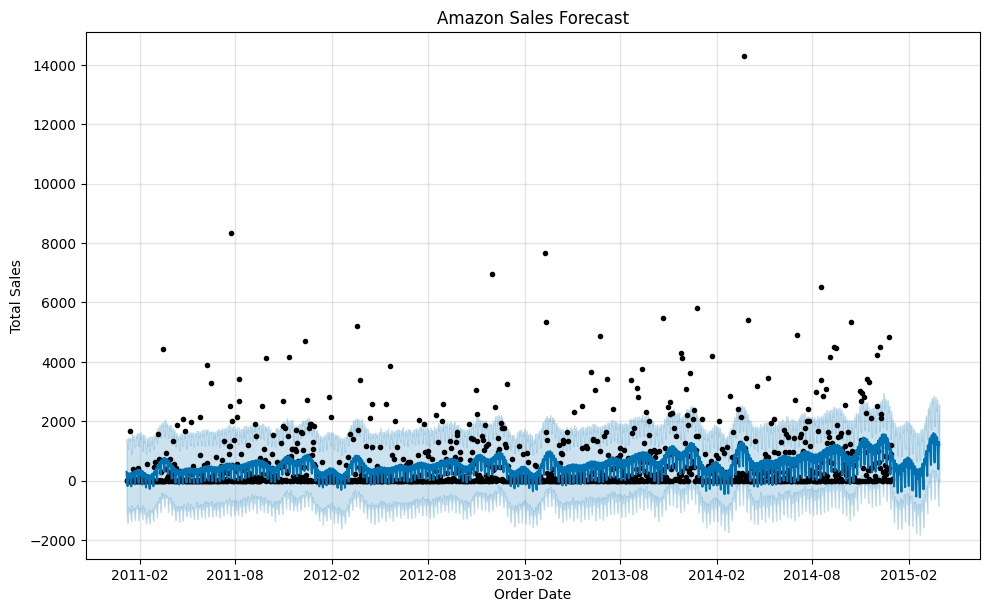

In [14]:
# 7. Plot the overall forecast
fig1 = model.plot(forecast)
plt.title('Amazon Sales Forecast')
plt.xlabel('Order Date')
plt.ylabel('Total Sales')
plt.show()

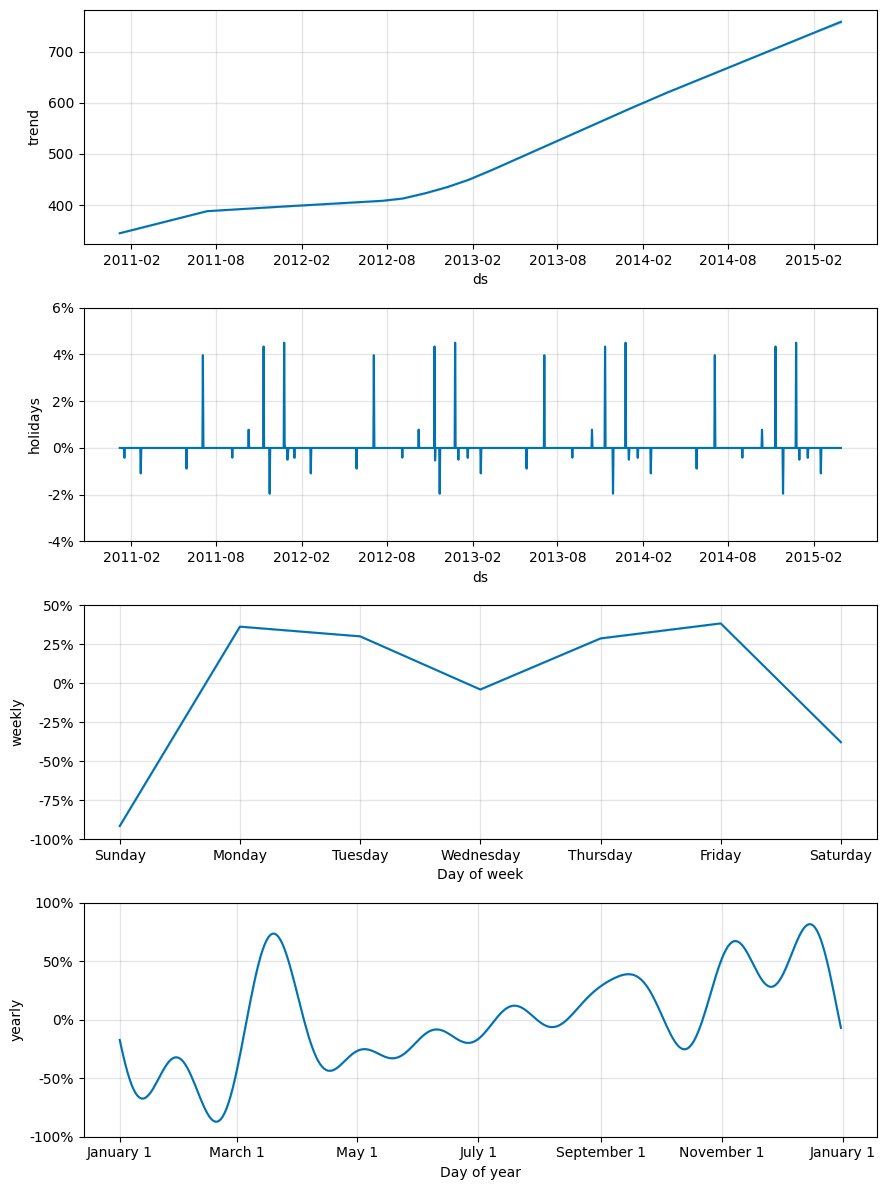

In [15]:
# 8. Plot the seasonal trends breakdown (Trend, Holidays, Weekly, Yearly)
fig2 = model.plot_components(forecast)
plt.show()

In [18]:
# split the data into train and test
from sklearn.model_selection import train_test_split

amazon_analysis = df.copy()

# classification to classify the selling metrics into four categories under performance feature
# High Sale, High Profit  # seller can focus sourcing in this category a lot
# Low Sale, High Profit.  # seller have to be aware of restoking the items at a specific quantity
# High Sale, Low Profit.  # focus on this when the seller have extra capital or cash
# Low Sale, Low Profit.   # last resort if the seller have numerous stalled cash
sales_median = amazon_analysis['Sales'].median()
profit_median = amazon_analysis['Profit'].median()

conditions = [
    (amazon_analysis['Sales'] >= sales_median) & (amazon_analysis['Profit'] >= profit_median),
    (amazon_analysis['Sales'] < sales_median) & (amazon_analysis['Profit'] >= profit_median),
    (amazon_analysis['Sales'] >= sales_median) & (amazon_analysis['Profit'] < profit_median),
    (amazon_analysis['Sales'] < sales_median) & (amazon_analysis['Profit'] < profit_median)
]

categories = [
    'High Sale, High Profit',
    'Low Sale, High Profit',
    'High Sale, Low Profit',
    'Low Sale, Low Profit'
]

amazon_analysis["Performance"] = np.select(
    conditions,
    categories,
    default = 'unknown'
)

# X = amazon_analysis[['']]
# Y = amazon_analysis['Performance']

,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit,Performance
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714,"Low Sale, Low Profit"
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694,"Low Sale, High Profit"
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656,"Low Sale, Low Profit"
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152,"High Sale, High Profit"
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825,"Low Sale, Low Profit"
...,...,...,...,...,...,...,...,...,...,...,...
3198,CA-2013-125794,2013-09-30,2013-10-04,MarisLaWare@gmail.com,"United States,Los Angeles,California",Accessories,Memorex Mini Travel Drive 64 GB USB 2.0 Flash ...,36.240,1,15.2208,"Low Sale, High Profit"
3199,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,15.6332,"High Sale, High Profit"
3200,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Phones,Aastra 57i VoIP phone,258.576,2,19.3932,"High Sale, High Profit"
3201,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,13.3200,"Low Sale, High Profit"
